# 01 · Overview of first names (Censo 2022)

Loads `data/nomes_censo2022_nomes.jsonl` and displays summary statistics,
a top-20 bar chart and the cumulative-coverage curve. All plots are rendered
inline and **stay embedded in this notebook** (outputs are not cleared).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebooks live in test/; the datasets live in ../data/
DATA = Path("..") / "data"
NOMES_PATH = DATA / "nomes_censo2022_nomes.jsonl"
SOBRENOMES_PATH = DATA / "nomes_censo2022_sobrenomes.jsonl"
POP_BR_2022 = 203_080_756

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

def load_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return pd.DataFrame([json.loads(line) for line in fh])

print("nomes:     ", NOMES_PATH.resolve())
print("sobrenomes:", SOBRENOMES_PATH.resolve())


nomes:      /home/user/nomescenso2022/data/nomes_censo2022_nomes.jsonl
sobrenomes: /home/user/nomescenso2022/data/nomes_censo2022_sobrenomes.jsonl


In [2]:
nomes = load_jsonl(NOMES_PATH)
print("rows:", len(nomes))
print("columns:", list(nomes.columns))
nomes.head(10)

rows: 128458
columns: ['rank', 'nome', 'frequencia', 'percent']


,rank,nome,frequencia,percent
0,1,maria,12284478,6.0491
1,2,jose,5164752,2.5432
2,3,ana,3948650,1.9444
3,4,joao,3430608,1.6893
4,5,antonio,2241094,1.1035
5,6,francisco,1665494,0.8201
6,7,pedro,1624478,0.7999
7,8,carlos,1474492,0.7261
8,9,lucas,1341525,0.6606
9,10,luiz,1335098,0.6574


In [3]:
summary = pd.DataFrame({
    "metric": ["registros", "rank máximo", "frequência total", "frequência mín.", "frequência máx.", "percent soma"],
    "valor": [len(nomes), nomes["rank"].max(), int(nomes["frequencia"].sum()),
              int(nomes["frequencia"].min()), int(nomes["frequencia"].max()), round(nomes["percent"].sum(), 2)],
})
summary

,metric,valor
0,registros,1.284580e+05
1,rank máximo,1.241800e+05
2,frequência total,1.903832e+08
3,frequência mín.,2.000000e+01
4,frequência máx.,1.228448e+07
5,percent soma,9.231000e+01


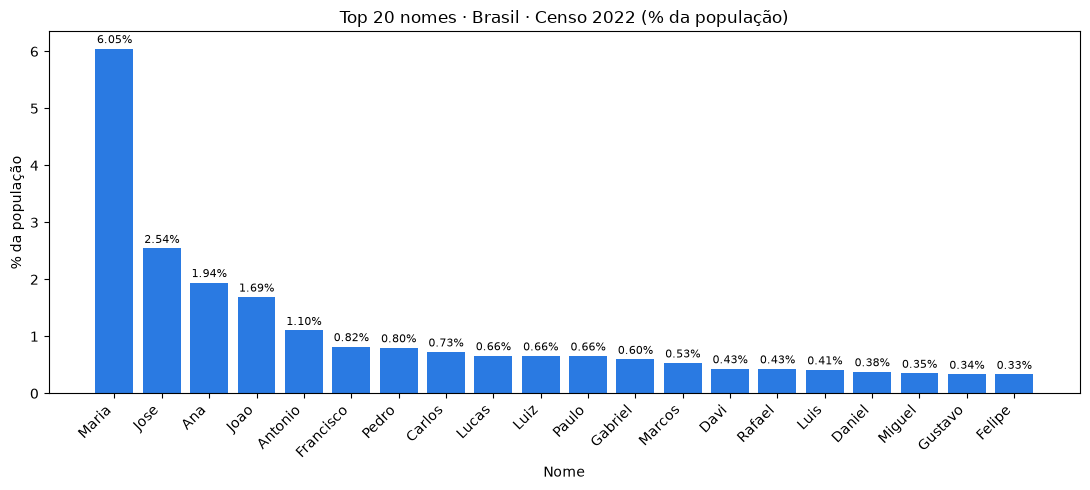

In [4]:
top20 = nomes.head(20)
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(top20["nome"].str.title(), top20["percent"], color="#2a7ae2")
ax.bar_label(bars, fmt="%.2f%%", fontsize=8, padding=2)
ax.set_title("Top 20 nomes · Brasil · Censo 2022 (% da população)")
ax.set_ylabel("% da população")
ax.set_xlabel("Nome")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

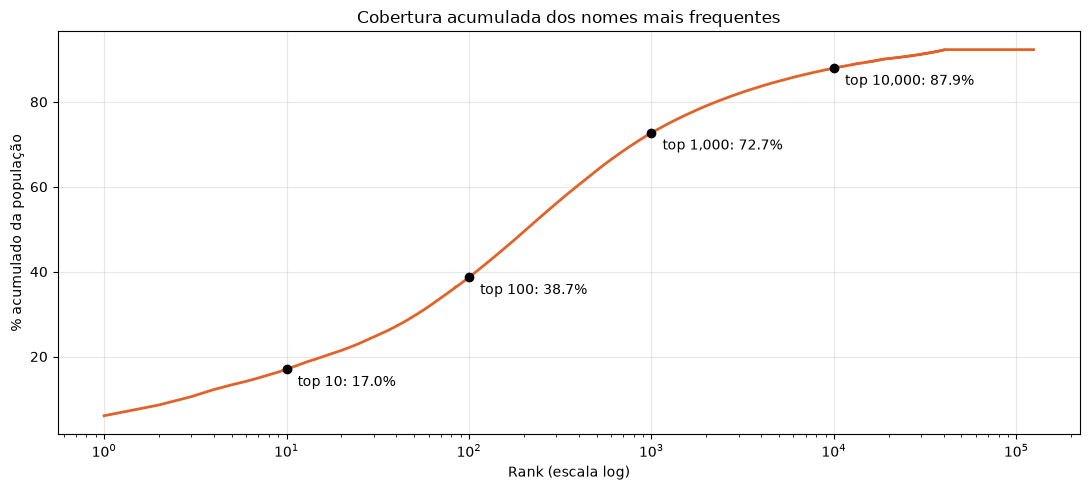

In [5]:
import numpy as np
cum = nomes["percent"].cumsum()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(nomes["rank"], cum, color="#e2632a", lw=2)
for n in (10, 100, 1000, 10000):
    if n <= len(cum):
        v = cum.iloc[n - 1]
        ax.scatter([n], [v], zorder=3, color="black")
        ax.annotate(f"top {n:,}: {v:.1f}%", (n, v), textcoords="offset points", xytext=(8, -12))
ax.set_xscale("log")
ax.set_xlabel("Rank (escala log)")
ax.set_ylabel("% acumulado da população")
ax.set_title("Cobertura acumulada dos nomes mais frequentes")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

In [6]:
# Share of the population covered by the top N names, as a table
rows = []
for n in (1, 10, 100, 1000, 10000, len(nomes)):
    rows.append({"top N": n, "% da população coberta": round(cum.iloc[n - 1], 2)})
pd.DataFrame(rows)

,top N,% da população coberta
0,1,6.05
1,10,16.99
2,100,38.66
3,1000,72.70
4,10000,87.95
5,128458,92.31
